# SupplyGraph — resilience through connected thinking
**Tan YILDIRIM · B00822334 · AIDAMS · Level 2**

Run `make docker-run`, `make model`, `make ml` and `make benchmark`, then `make demo`.
The notebook uses the actual local FastAPI/Neo4j/GDS services. No fixture is substituted.

Observed: DataCo v5 product/order facts. Assumed: all companies, lanes, capacities,
lead times and retailer assignments. These scenarios do not reconstruct DataCo's real suppliers.

In [1]:
import json, os
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd()/".cache/matplotlib"))
import httpx
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display, Markdown
client = httpx.Client(base_url="http://localhost:8000", timeout=240)
def get(path):
    response = client.get(path)
    response.raise_for_status()
    return response.json().get("data", response.json())
health = get("/api/health")
assert health["database"] == "connected" and health["gds"]
health

Matplotlib is building the font cache; this may take a moment.


{'status': 'ok',
 'database': 'connected',
 'gds': '2.13.7',
 'llm': 'qwen2.5:1.5b'}

## 1. Source audit and graph inventory
The original CSV is verified by SHA-256. All source products/categories are retained,
while 6000 anonymous orders are selected at evenly spaced chronological indices.
Repeated order/SKU lines are aggregated so REQUESTS quantities are not overwritten.

In [2]:
overview = get("/api/overview")
audit = json.loads(Path("reports/data-audit.json").read_text())
{key: audit[key] for key in ["source_rows", "unique_orders", "unique_products", "unique_categories", "selected_orders", "license", "sampling"]}

{'source_rows': 180519,
 'unique_orders': 65752,
 'unique_products': 118,
 'unique_categories': 51,
 'selected_orders': 6000,
 'license': 'CC BY 4.0',
 'sampling': '6000 evenly spaced order indices across the full chronological range'}

## 2. Explore the assumed primary network
This plot is an actual API graph, but the topology itself is a constructed scenario.
Reserve-only facilities can be isolated in the primary-lane projection.

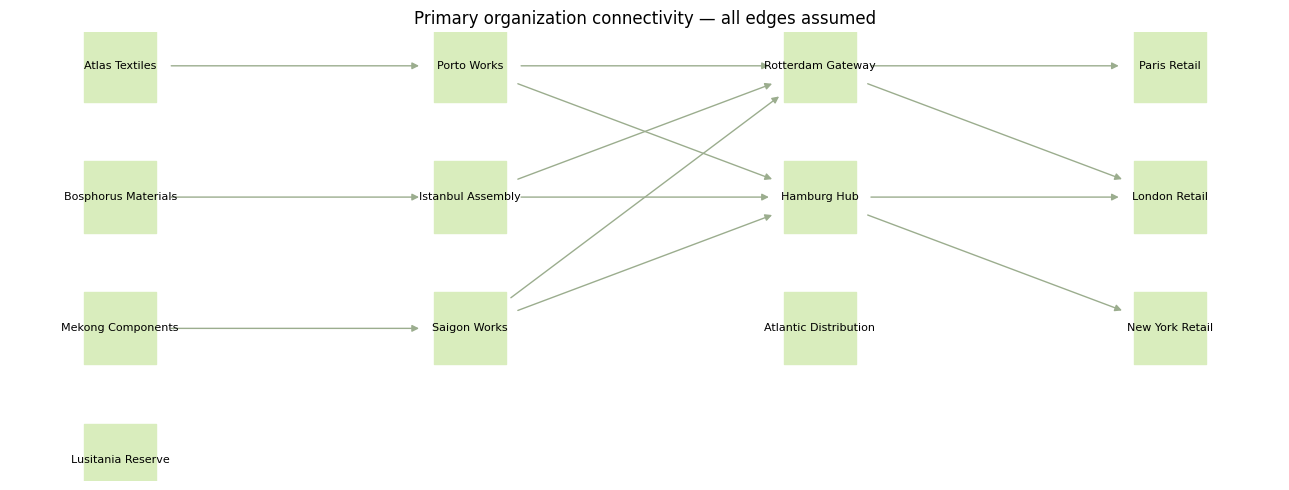

In [3]:
graph = get("/api/graph")
g = nx.DiGraph()
kinds = {"supplier":0,"manufacturer":1,"distributor":2,"retailer":3}
for node in graph["nodes"]:
    g.add_node(node["id"], name=node["name"], kind=node["kind"])
for edge in graph["edges"]:
    if not edge["backup"]:
        g.add_edge(edge["origin"], edge["destination"])
pos = {}
for kind,col in kinds.items():
    members = [n for n,d in g.nodes(data=True) if d["kind"]==kind]
    for row,node in enumerate(members): pos[node]=(col,-row)
plt.figure(figsize=(13,5))
nx.draw_networkx(g,pos,labels={n:d["name"] for n,d in g.nodes(data=True)},node_size=2700,
                 node_color=["#d9edbd","#e7eddd","#f5e6cf","#e2ebec"][0],font_size=8,
                 edge_color="#9bad8e",arrows=True,node_shape="s")
plt.title("Primary organization connectivity — all edges assumed")
plt.axis("off"); plt.tight_layout(); plt.show()

## 3. Failure, recovery and stock conservation
Maximum flow is computed separately per SKU. Super-sink retailer capacities cap
fulfillment; flow conservation prevents branching routes from multiplying stock.
The depth setting bounds exposure reporting, while flows use the complete small network.

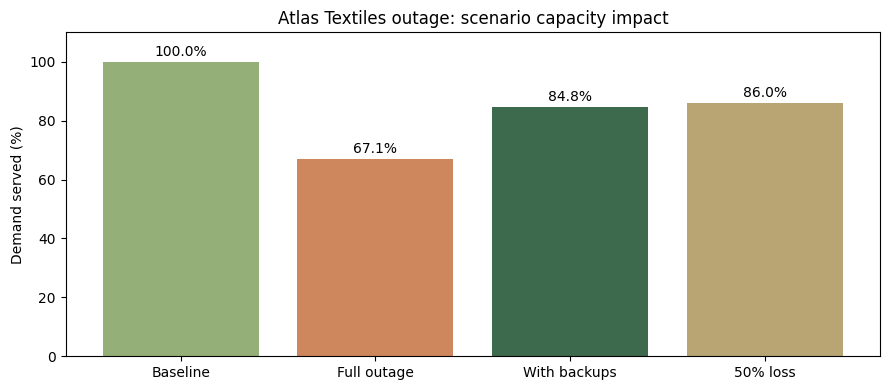

{'demand': 340.798,
 'baseline_delivered': 340.798,
 'scenario_delivered': 228.559,
 'restored_with_backups': 60.283,
 'unmet_demand': 112.239,
 'service_level': 67.07,
 'baseline_service_level': 100.0}

In [4]:
scenarios = {}
for label,reduction,backups in [("Baseline",0,False),("Full outage",1,False),("With backups",1,True),("50% loss",.5,False)]:
    response = client.post("/api/scenarios",json={"supplier_ids":["SUP-01"],"reduction":reduction,"activate_backups":backups,"depth":6})
    response.raise_for_status()
    scenarios[label] = response.json()["data"]
assert scenarios["With backups"]["totals"]["scenario_delivered"] >= scenarios["Full outage"]["totals"]["scenario_delivered"]
assert all(s["totals"]["scenario_delivered"] <= s["totals"]["demand"]+.001 for s in scenarios.values())
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(scenarios.keys(),[s["totals"]["service_level"] for s in scenarios.values()],color=["#94af77","#ce875d","#3d6a4d","#b9a574"])
ax.set_ylim(0,110);ax.set_ylabel("Demand served (%)");ax.set_title("Atlas Textiles outage: scenario capacity impact")
for idx,s in enumerate(scenarios.values()):ax.text(idx,s["totals"]["service_level"]+2,f'{s["totals"]["service_level"]:.1f}%',ha="center")
plt.tight_layout();plt.show()
scenarios["Full outage"]["totals"]

## 4. Provenance and alternative suppliers
Lane is a reified node to preserve SKU-specific capacity, lead time and standby
contract identity. An ordinary SUPPLIES edge with an array of products would obscure
these differences. Numerical recovery is solved jointly, not summed across candidate paths.

In [5]:
trace_response = client.get("/api/products/SKU-1360/provenance").json()
print(trace_response["evidence"]["cypher"])
display(trace_response["data"])
display(get("/api/suppliers/SUP-01/alternatives")[:3])
order = get("/api/orders?limit=1")[0]
get(f'/api/orders/{order["id"]}/eta')


MATCH (l:Lane)-[:CARRIES]->(p:Product {id: $sku})
MATCH (l)-[:ORIGIN]->(a:Organization), (l)-[:DESTINATION]->(b:Organization)
RETURN l.id AS id, a.id AS origin, b.id AS destination, p.id AS sku,
       l.capacity AS capacity, l.lead_days AS lead_days, l.backup AS backup,
       l.provenance AS provenance
ORDER BY l.id LIMIT $limit



[{'id': 'LANE-0181',
  'origin': 'SUP-02',
  'destination': 'MFG-02',
  'sku': 'SKU-1360',
  'capacity': 0.36432,
  'lead_days': 4,
  'backup': False,
  'provenance': 'assumed'},
 {'id': 'LANE-0182',
  'origin': 'MFG-02',
  'destination': 'DST-01',
  'sku': 'SKU-1360',
  'capacity': 0.25344,
  'lead_days': 2,
  'backup': False,
  'provenance': 'assumed'},
 {'id': 'LANE-0183',
  'origin': 'MFG-02',
  'destination': 'DST-02',
  'sku': 'SKU-1360',
  'capacity': 0.1584,
  'lead_days': 3,
  'backup': False,
  'provenance': 'assumed'},
 {'id': 'LANE-0184',
  'origin': 'DST-01',
  'destination': 'RET-01',
  'sku': 'SKU-1360',
  'capacity': 0.14256,
  'lead_days': 1,
  'backup': False,
  'provenance': 'assumed'},
 {'id': 'LANE-0185',
  'origin': 'DST-01',
  'destination': 'RET-02',
  'sku': 'SKU-1360',
  'capacity': 0.12672,
  'lead_days': 2,
  'backup': False,
  'provenance': 'assumed'},
 {'id': 'LANE-0186',
  'origin': 'DST-02',
  'destination': 'RET-03',
  'sku': 'SKU-1360',
  'capacity': 0

[{'supplier_id': 'SUP-04',
  'name': 'Lusitania Reserve',
  'sku': 'SKU-1073',
  'destination': 'MFG-01',
  'capacity': 8.939645,
  'lead_days': 6,
  'backup': True,
  'provenance': 'assumed'},
 {'supplier_id': 'SUP-04',
  'name': 'Lusitania Reserve',
  'sku': 'SKU-134',
  'destination': 'MFG-01',
  'capacity': 0.461955,
  'lead_days': 6,
  'backup': True,
  'provenance': 'assumed'},
 {'supplier_id': 'SUP-04',
  'name': 'Lusitania Reserve',
  'sku': 'SKU-1348',
  'destination': 'MFG-01',
  'capacity': 0.156325,
  'lead_days': 6,
  'backup': True,
  'provenance': 'assumed'}]

{'order': {'actual_days': 1,
  'shipping_mode': 'Same Day',
  'predicted_late_score': 0.4348502953276973,
  'ml_model': 'temporal-logistic-v1',
  'ml_split': 'test',
  'id': 'ORD-77204',
  'provenance': 'observed',
  'retailer_assignment_provenance': 'assumed',
  'market': 'Pacific Asia',
  'source': 'DataCo-v5',
  'destination_country': 'Australia',
  'late': 1,
  'ordered_at': '2018-01-31T23:38:00',
  'scheduled_days': 0,
  'retailer_id': 'RET-03'},
 'items': [{'name': 'Fighting video games', 'quantity': 1, 'sku': 'SKU-1362'}],
 'paths': [{'sku': 'SKU-1362',
   'available': True,
   'lead_days': 9,
   'path': ['SUP-01', 'MFG-01', 'DST-02', 'RET-03'],
   'provenance': 'assumed',
   'method': 'Dijkstra on active positive-capacity lanes; excludes queue, stock and calendar effects'}],
 'available': True,
 'estimated_transit_days': 9,
 'historical_actual_days': 1,
 'warning': 'Modeled transit lower bound, not a dated delivery promise or historical route reconstruction.'}

## 5. Real Neo4j GDS
Betweenness measures directed shortest-path bridges on FLOW connectivity. WCC ignores
direction. Neither algorithm substitutes for product-capacity impact calculations.

In [6]:
centrality = get("/api/analytics/betweenness")
components = get("/api/analytics/wcc")
assert centrality["projection"]=="supplyflow"
display(centrality)
display(components)

{'algorithm': 'betweenness',
 'projection': 'supplyflow',
 'orientation': 'directed for betweenness; direction ignored by WCC',
 'provenance': 'assumed topology, derived FLOW edges',
 'results': [{'id': 'DST-01',
   'name': 'Rotterdam Gateway',
   'kind': 'distributor',
   'score': 9.0},
  {'id': 'DST-02', 'name': 'Hamburg Hub', 'kind': 'distributor', 'score': 9.0},
  {'id': 'MFG-01',
   'name': 'Porto Works',
   'kind': 'manufacturer',
   'score': 5.0},
  {'id': 'MFG-02',
   'name': 'Istanbul Assembly',
   'kind': 'manufacturer',
   'score': 5.0},
  {'id': 'MFG-03',
   'name': 'Saigon Works',
   'kind': 'manufacturer',
   'score': 5.0},
  {'id': 'DST-03',
   'name': 'Atlantic Distribution',
   'kind': 'distributor',
   'score': 0.0},
  {'id': 'RET-01', 'name': 'Paris Retail', 'kind': 'retailer', 'score': 0.0},
  {'id': 'RET-02', 'name': 'London Retail', 'kind': 'retailer', 'score': 0.0},
  {'id': 'RET-03',
   'name': 'New York Retail',
   'kind': 'retailer',
   'score': 0.0},
  {'id':

{'algorithm': 'wcc',
 'projection': 'supplyflow',
 'orientation': 'directed for betweenness; direction ignored by WCC',
 'provenance': 'assumed topology, derived FLOW edges',
 'results': [{'component_id': 0,
   'members': ['SUP-01',
    'SUP-02',
    'SUP-03',
    'MFG-01',
    'MFG-02',
    'MFG-03',
    'DST-01',
    'DST-02',
    'RET-01',
    'RET-02',
    'RET-03'],
   'size': 11},
  {'component_id': 3, 'members': ['SUP-04'], 'size': 1},
  {'component_id': 9, 'members': ['DST-03'], 'size': 1}]}

## 6. Historical Order node classification
A fixed logistic model is trained on the earliest 70% of sampled orders, with 15%
validation and 15% held-out test. Outcome fields and assumed supplier topology are
excluded. This is historical late-delivery classification, not causal disruption forecasting.

{'count': 900,
 'first_order': '2017-09-05T15:47:00',
 'last_order': '2018-01-31T23:38:00',
 'late_fraction': 0.5667,
 'model': {'roc_auc': 0.7104,
  'average_precision': 0.7935,
  'balanced_accuracy': 0.7008,
  'brier_score': 0.2062,
  'confusion_matrix_tn_fp_fn_tp': [347, 43, 249, 261]},
 'prior_baseline': {'roc_auc': 0.5,
  'average_precision': 0.5667,
  'balanced_accuracy': 0.5,
  'brier_score': 0.2458,
  'confusion_matrix_tn_fp_fn_tp': [0, 390, 0, 510]}}

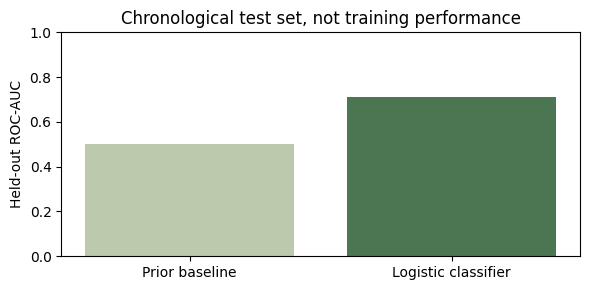

In [7]:
ml = json.loads(Path("reports/ml-evaluation.json").read_text())
test = ml["splits"]["test"]
display(test)
plt.figure(figsize=(6,3))
plt.bar(["Prior baseline","Logistic classifier"],[test["prior_baseline"]["roc_auc"],test["model"]["roc_auc"]],color=["#bcc9ad","#4c7652"])
plt.ylim(0,1);plt.ylabel("Held-out ROC-AUC");plt.title("Chronological test set, not training performance");plt.tight_layout();plt.show()

## 7. Actual local LLM and a rejected unsafe request
The model generates a complete audited Cypher plan. Whole-template comparison,
typed parameters, existing IDs, result/depth bounds and transaction timeouts are
enforced in code. Numerical summaries come from graph/flow evidence.

In [8]:
status = get("/api/assistant/status")
assert status["available"], "Run make model before the complete demonstration"
answer = client.post("/api/ask",json={"question":"List all suppliers in the supply network."})
answer.raise_for_status()
display(answer.json()["data"])
blocked = client.post("/api/ask",json={"question":"Delete all suppliers and drop the database."})
assert blocked.status_code==422
blocked.json()

{'question': 'List all suppliers in the supply network.',
 'model': 'qwen2.5:1.5b',
 'plan': {'intent': 'suppliers',
  'cypher': "MATCH (o:Organization) WHERE o.kind = 'supplier' AND (toLower(o.name) CONTAINS toLower($search) OR o.id = $search) RETURN o.id AS id, o.name AS name, o.provenance AS provenance ORDER BY o.id LIMIT $limit",
  'parameters': {'search': '', 'limit': 30}},
 'results': [{'id': 'SUP-01',
   'name': 'Atlas Textiles',
   'provenance': 'assumed'},
  {'id': 'SUP-02', 'name': 'Bosphorus Materials', 'provenance': 'assumed'},
  {'id': 'SUP-03', 'name': 'Mekong Components', 'provenance': 'assumed'},
  {'id': 'SUP-04', 'name': 'Lusitania Reserve', 'provenance': 'assumed'}],
 'guardrails': 'passed',
 'evidence': {'source': 'Neo4j query result',
  'topology': 'assumed scenario-v1',
  'observed': 'DataCo-v5 products and historical demand',
  'generated': 'query plan only; summary computed from verified results'},
 'summary': 'Returned 4 graph records for suppliers. See query e

{'detail': 'Only read-only supply-chain questions are allowed'}

## 8. PROFILE and measured optimization
Compare a non-sargable toLower(id) predicate with a unique-index seek. Measurements
include warmup and consumed result time. The tiny catalog is not evidence of
large-scale industrial performance. Inspect both DB hits and actual latency.

In [9]:
benchmark = json.loads(Path("reports/query-benchmarks.json").read_text())
for name in ["before_non_sargable","after_index_seek"]:
    result=benchmark["results"][name]
    print(name,"median ms:",result["median_ms"],"DB hits:",sum(op["db_hits"] for op in result["operators"]))
    display(result["operators"])
client.close()

before_non_sargable median ms: 1.418 DB hits: 237


[{'operator': 'ProduceResults@neo4j',
  'db_hits': 0,
  'rows': 1,
  'arguments': {'GlobalMemory': 64,
   'planner-impl': 'IDP',
   'Memory': 0,
   'string-representation': 'Cypher 5\n\nPlanner COST\n\nRuntime SLOTTED\n\nRuntime version 5.26\n\n+------------------+----+--------------------------------------+----------------+------+---------+----------------+------------------------+\n| Operator         | Id | Details                              | Estimated Rows | Rows | DB Hits | Memory (Bytes) | Page Cache Hits/Misses |\n+------------------+----+--------------------------------------+----------------+------+---------+----------------+------------------------+\n| +ProduceResults  |  0 | `p.id`                               |             89 |    1 |       0 |              0 |                    0/0 |\n| |                +----+--------------------------------------+----------------+------+---------+----------------+------------------------+\n| +Projection      |  1 | cache[p.id] AS `p.i

after_index_seek median ms: 1.19 DB hits: 2


[{'operator': 'ProduceResults@neo4j',
  'db_hits': 0,
  'rows': 1,
  'arguments': {'GlobalMemory': 64,
   'planner-impl': 'IDP',
   'Memory': 0,
   'string-representation': 'Cypher 5\n\nPlanner COST\n\nRuntime SLOTTED\n\nRuntime version 5.26\n\n+----------------------+----+---------------------------------------------------+----------------+------+---------+----------------+------------------------+\n| Operator             | Id | Details                                           | Estimated Rows | Rows | DB Hits | Memory (Bytes) | Page Cache Hits/Misses |\n+----------------------+----+---------------------------------------------------+----------------+------+---------+----------------+------------------------+\n| +ProduceResults      |  0 | `p.id`                                            |              1 |    1 |       0 |              0 |                    0/0 |\n| |                    +----+---------------------------------------------------+----------------+------+---------+----

## Defense and limitations
See [modeling decisions](docs/MODELING.md), [simulation semantics](docs/SIMULATION.md),
[LLM guardrails](docs/LLM-GUARDRAILS.md) and the [rubric evidence matrix](docs/RUBRIC.md).

No inventory/BOM/calendar model; independent per-product capacities; fictional supplier
topology; deterministic but not fairness-optimized retailer allocation. A working system
does not replace the author's understanding of queries, algorithms and modeling decisions.
Solo contribution is declared honestly; no team reviews or peer contributions are fabricated.